# 03 · Explainability and Fairness

A credit model has to answer two questions beyond accuracy:

1. **Why** did it give this customer this score? Customers, staff and regulators need reasons.
2. Is it **fair** across groups of customers, even though it never sees their demographics?

In [1]:
import numpy as np
import pandas as pd

from credit_risk import config, data, evaluation, explain, fairness, plots, train

plots.set_style()
pd.set_option("display.precision", 3)
FIG, TABLES = config.FIGURES_DIR, config.TABLES_DIR

meta = train.load_metadata()
model = train.load_model()
pred = pd.read_csv(TABLES / "predictions.csv")
oof, test = pred[pred["split"] == "train_oof"], pred[pred["split"] == "test"]
threshold = meta["decision"]["threshold"]

df = data.load_clean()
_, test_df = data.split(df)
X_test = test_df[config.BEHAVIOUR]
reference = pd.Series(meta["reference_profile"])[config.BEHAVIOUR]

## 1. What the model relies on overall

**Grouped permutation importance:** shuffle a whole group of related inputs (e.g. all six monthly balances) and measure how much ROC-AUC drops. Grouping matters because the engineered features combine several raw columns.

,group,auc_drop,auc_drop_std
0,Latest repayment status (Sep),0.075,0.004
1,Earlier repayment history (Apr-Aug),0.044,0.003
2,Recent payment amounts,0.033,0.002
3,Outstanding balances,0.028,0.003
4,Credit limit,0.022,0.004


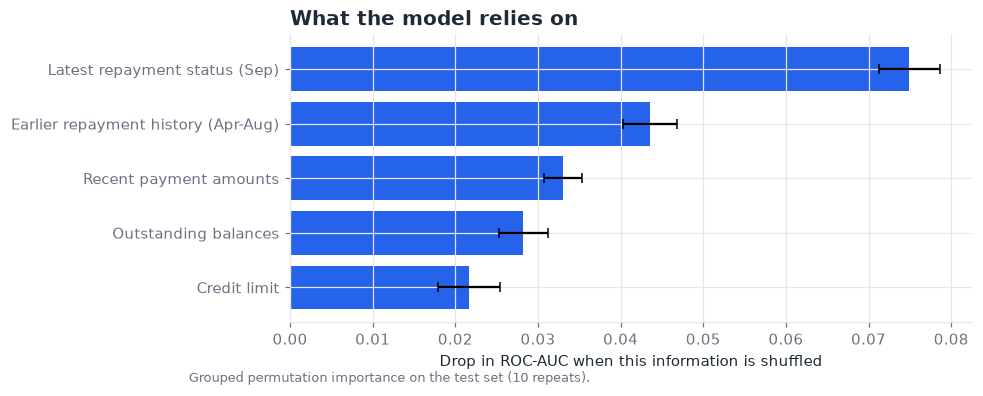

In [2]:
imp = pd.read_csv(TABLES / "importance.csv")
plots.importance(imp, FIG / "07_importance.png")
imp

The **latest repayment status** matters most, followed by the earlier repayment history. Balances, payment amounts and credit limit each add a smaller amount. This matches the data exploration in notebook 01, and it matches how credit risk works in practice: recent behaviour is the best guide to near-term behaviour.

## 2. Why this customer? Reason codes

For one customer, each group of inputs is replaced by the profile of a *typical customer who paid* (the median of non-defaulters), and the customer is re-scored. The change in probability is that factor's contribution. Three test customers at different risk levels:

,ID,LIMIT_BAL,PAY_1,PAY_2,PAY_3,BILL_AMT1,PAY_AMT1,default
Low risk,9230,390000,0,0,0,178087,10000,0
Medium risk,13923,40000,0,0,0,35225,1933,1
Very high risk,21702,70000,2,0,0,19112,1629,1


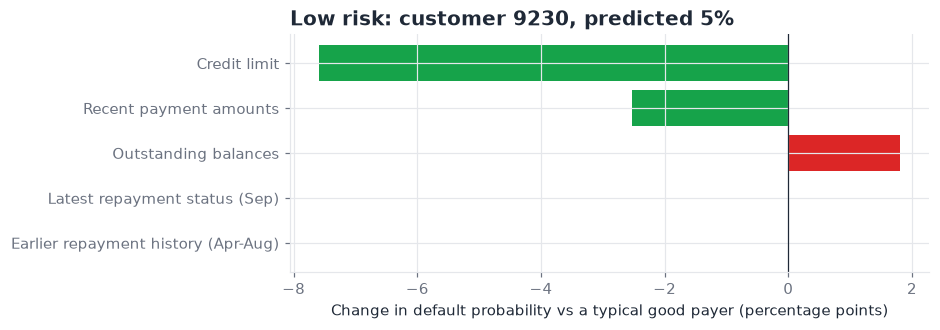

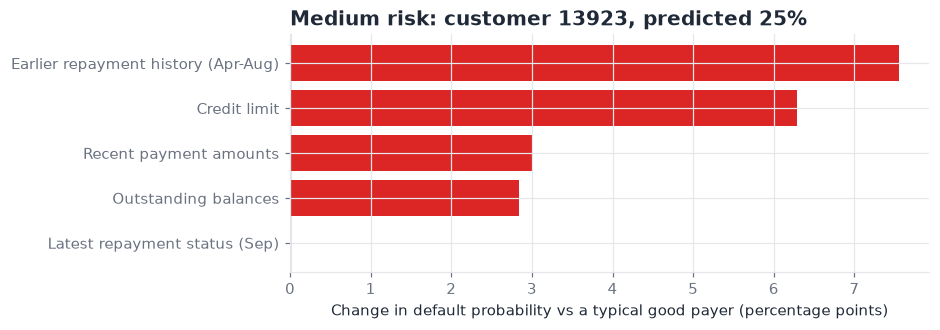

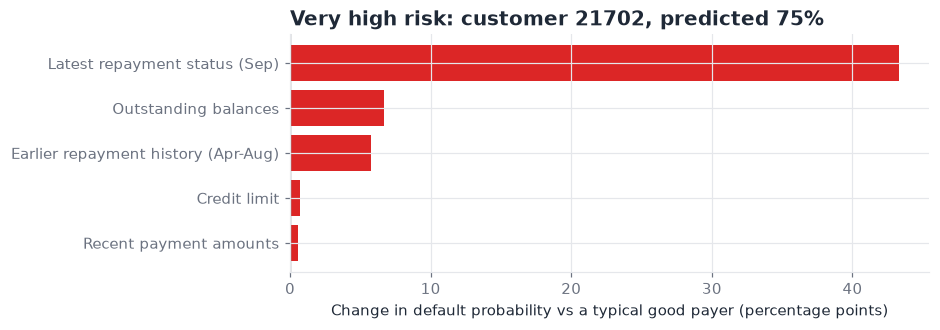

In [3]:
p = test_df.assign(probability=model.predict_proba(X_test)[:, 1])
examples = {label: (p["probability"] - target).abs().idxmin()
            for label, target in [("Low risk", 0.05), ("Medium risk", 0.25), ("Very high risk", 0.75)]}
shown = []
for i, (label, idx) in enumerate(examples.items(), start=8):
    customer = X_test.loc[[idx]]
    reasons = explain.reason_codes(model, customer, reference)
    prob = reasons["probability"].iloc[0]
    plots.reasons(reasons, f"{label}: customer {test_df.loc[idx, 'ID']}, predicted {prob:.0%}",
                  FIG / f"{i:02d}_reasons_{label.split()[0].lower()}.png")
    shown.append(test_df.loc[idx, ["ID", "LIMIT_BAL", "PAY_1", "PAY_2", "PAY_3", "BILL_AMT1", "PAY_AMT1", config.TARGET]]
                 .rename(label))
pd.DataFrame(shown)

The explanations are concrete: a very high-risk customer is driven mainly by their latest repayment status, while for a low-risk customer the same factors *lower* the risk below that of a typical payer. In the app, these appear as plain-language reasons next to each score.

*Limitation:* replacing one group at a time can't fully capture interactions between groups. It is a deliberately simple method that is easy to explain and verify; SHAP values would be the more rigorous next step.

## 3. Fairness audit

At the chosen threshold, outcome rates by sex, age, education and marital status (test set; groups with fewer than 100 customers are not shown):

customers  default_rate  mean_predicted  \
               group                                                      
Sex            Female                3598         0.213           0.216   
               Male                  2402         0.234           0.229   
Age            21-30                 2181         0.220           0.233   
               31-40                 2105         0.210           0.209   
               41-50                 1243         0.235           0.216   
               51-60                  413         0.245           0.237   
Education      Graduate school       2130         0.190           0.192   
               High school           1014         0.257           0.244   
               University            2774         0.236           0.238   
Marital status Married               2767         0.241           0.221   
               Single                3158         0.205           0.222   

                                calibration_gap  flagged_rate  recall  \
               group                                                    
Sex            Female                 3.409e-03         0.412   0.717   
               Male                  -4.802e-03         0.443   0.734   
Age            21-30                  1.323e-02         0.455   0.775   
               31-40                 -5.533e-04         0.396   0.685   
               41-50                 -1.899e-02         0.412   0.702   
               51-60                 -7.727e-03         0.448   0.723   
Education      Graduate school        1.551e-03         0.361   0.711   
               High school           -1.293e-02         0.484   0.713   
               University             1.088e-03         0.456   0.738   
Marital status Married               -2.049e-02         0.415   0.719   
               Single                 1.672e-02         0.432   0.733   

                                false_positive_rate  
               group                                 
Sex            Female                         0.329  
               Male                           0.355  
Age            21-30                          0.365  
               31-40                          0.320  
               41-50                          0.323  
               51-60                          0.359  
Education      Graduate school                0.279  
               High school                    0.405  
               University                     0.369  
Marital status Married                        0.318  
               Single                         0.354

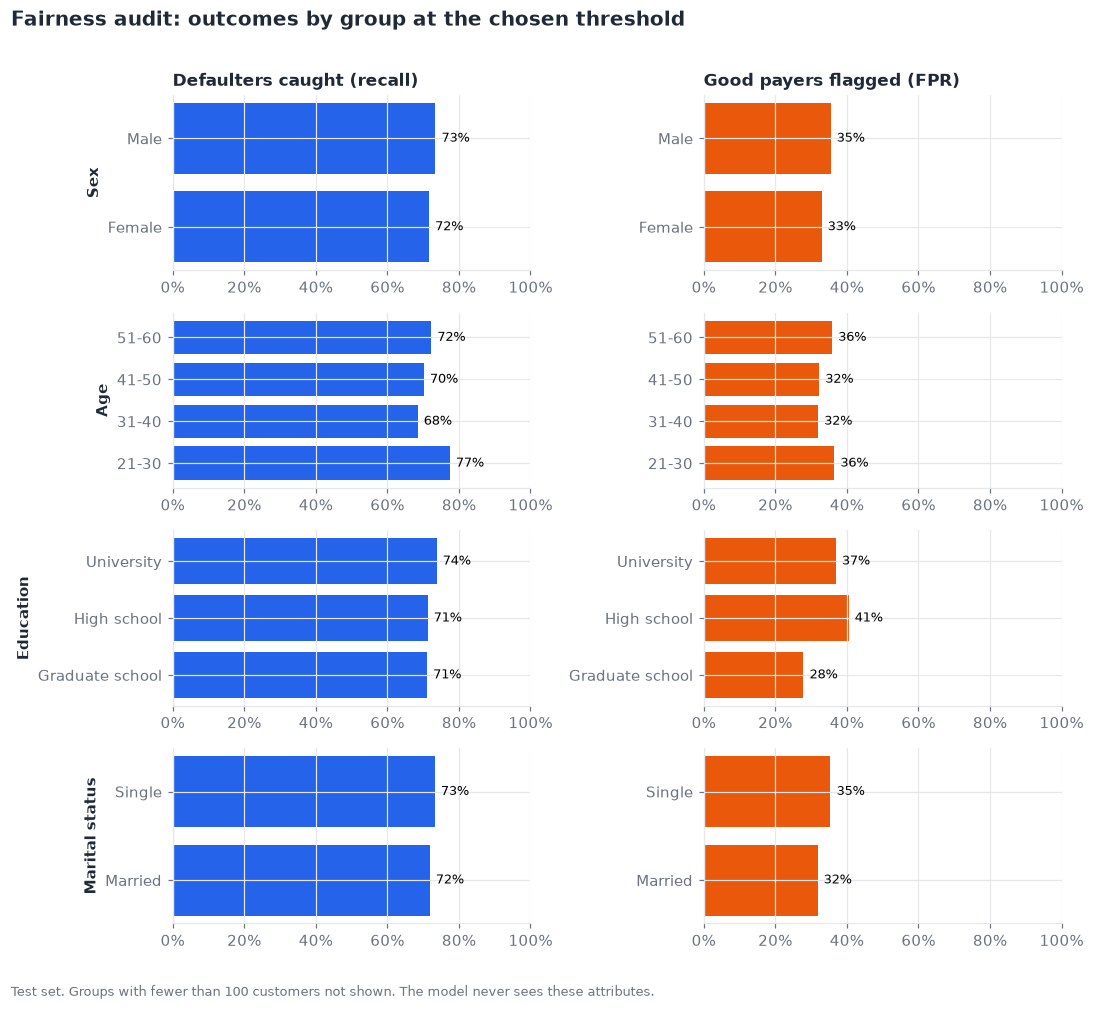

In [4]:
reports = {label: pd.read_csv(TABLES / f"fairness_{label.lower().replace(' ', '_')}.csv", index_col=0)
           for label in ["Sex", "Age", "Education", "Marital status"]}
plots.fairness(reports, FIG / "11_fairness.png")
pd.concat(reports)

In [5]:
gaps = pd.DataFrame({label: {
    "recall gap (pp)": 100 * (r["recall"].max() - r["recall"].min()),
    "false positive rate gap (pp)": 100 * (r["false_positive_rate"].max() - r["false_positive_rate"].min()),
    "largest calibration error (pp)": 100 * r["calibration_gap"].abs().max(),
    "default rate gap (pp)": 100 * (r["default_rate"].max() - r["default_rate"].min()),
} for label, r in reports.items()}).T.round(1)
gaps

,recall gap (pp),false positive rate gap (pp),largest calibration error (pp),default rate gap (pp)
Sex,1.8,2.5,0.5,2.1
Age,9.0,4.5,1.9,3.5
Education,2.7,12.6,1.3,6.7
Marital status,1.4,3.6,2.0,3.7


**Findings**

- **The model is well calibrated in every group**: predicted and actual default rates agree to within about 2 percentage points for every sex, age band, education level and marital status. A predicted 30% means about 30% for everyone.
- **Recall is similar across sexes** (gap about 2 points): defaulting men and women are caught at the same rate.
- **False positive rates differ more**, most clearly by education: good payers with a high-school education are flagged more often than those with a graduate degree (a gap of about 13 points). Age shows a smaller gap (about 9 points in recall, highest for 21–30).
- **These gaps follow differences in actual default rates** (19% for graduate school vs 26% for high school). When groups' true default rates differ, a model *cannot* be both well calibrated in every group and have equal false positive rates. This is a proven mathematical result, not a flaw of this model.

**What a bank should do with this:** decide explicitly which fairness criterion matters for this use. If the action is supportive (a repayment-plan offer), a higher flag rate does little harm. If it is punitive (a limit cut), the false-positive gap deserves attention, and group-specific thresholds or a human review step could be considered. That is a policy decision for the business and its regulators, not something to settle silently in code.